Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/tmp/ipykernel_1024/1352415804.py:8

Number of arms: 10

Epsilon-Greedy Results
-----------------------------
Q-values: [-0.09 -0.57 -0.11 -1.2  -2.88 -0.11 -0.1  -0.08 -0.25 -0.02]
Arm selection counts: [237   8  34   7   3  10  48  11  17 125]
Average reward: -0.11962881767990496


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


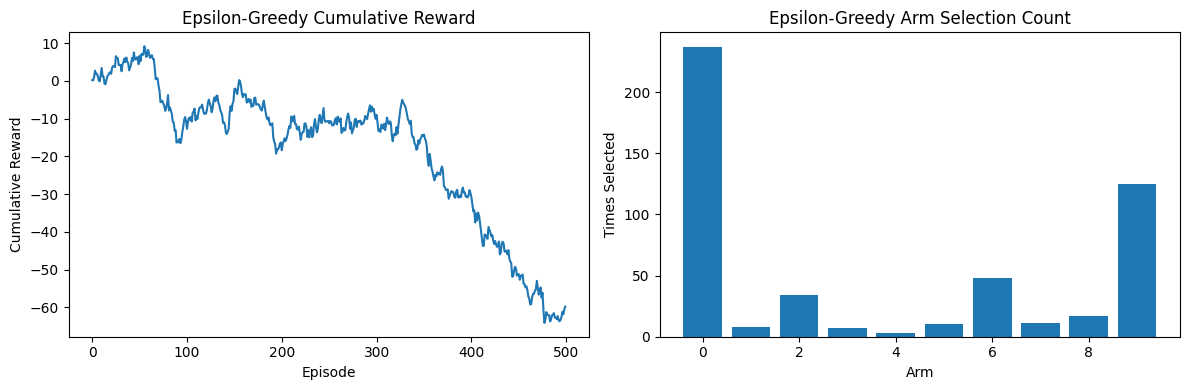


Softmax Results
-----------------------------
Q-values: [ 0.15 -0.03 -2.13  0.2   0.34  0.09  0.06 -0.3   0.09 -0.04]
Arm selection counts: [67 55  1 65 60 59 23 60 46 64]
Average reward: 0.061059407332856475


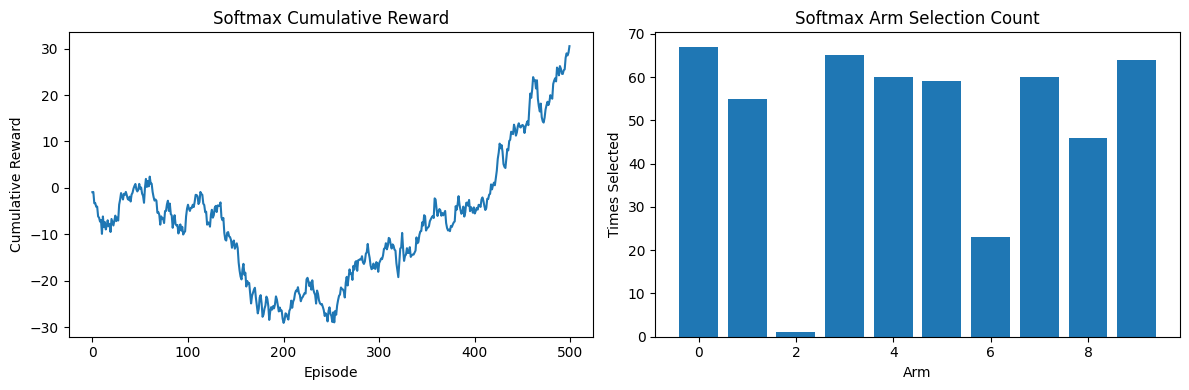

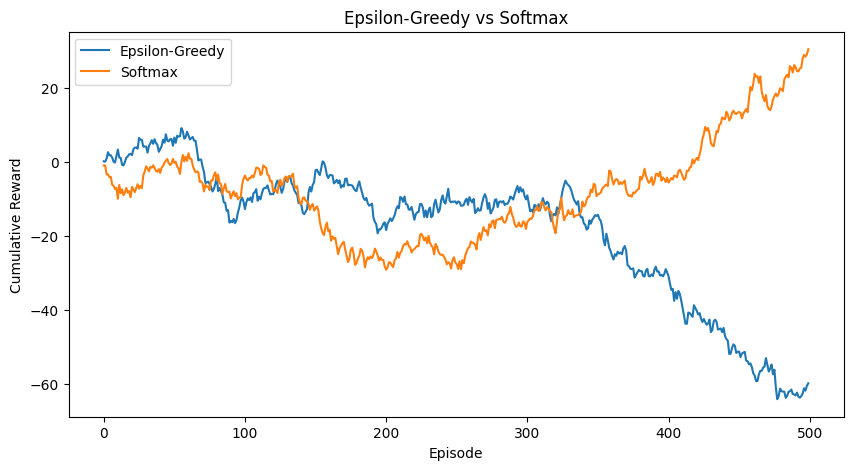

In [1]:
# Import the Gym package
import gym

# Import the Multi-Armed Bandit environments
import gym_bandits

# Import NumPy for numerical operations
import numpy as np

# Import Matplotlib for plotting graphs
import matplotlib.pyplot as plt

# Fix compatibility issue between NumPy and Gym
np.bool8 = np.bool_


# Create the Multi-Armed Bandit environment
base_env = gym.make("MultiarmedBandits-v0")

# Access the original environment without wrappers
env = base_env.unwrapped

# Get the total number of bandit arms
n_arms = env.action_space.n

# Set the total number of episodes
episodes = 500

# Display the number of available arms
print("Number of arms:", n_arms)


# Set exploration probability
epsilon = 0.1

# Initialize estimated Q-values for all arms
q_values = np.zeros(n_arms)

# Initialize the selection count for each arm
counts = np.zeros(n_arms)

# Store rewards obtained in each episode
rewards = []

# Repeat the experiment for all episodes
for episode in range(episodes):

    # Reset the environment before each episode
    env.reset()

    # Generate a random number to decide exploration or exploitation
    if np.random.rand() < epsilon:

        # Select a random arm (Exploration)
        action = env.action_space.sample()

    else:

        # Select the arm with the highest estimated reward (Exploitation)
        action = np.argmax(q_values)

    # Execute the selected action and receive the reward
    observation, reward, done, info = env.step(action)

    # Increase the count for the selected arm
    counts[action] += 1

    # Update the estimated Q-value using incremental averaging
    q_values[action] += (reward - q_values[action]) / counts[action]

    # Store the received reward
    rewards.append(reward)

# Display the results
print("\nEpsilon-Greedy Results")
print("-----------------------------")

# Print estimated Q-values
print("Q-values:", np.round(q_values, 2))

# Print how many times each arm was selected
print("Arm selection counts:", counts.astype(int))

# Print the average reward obtained
print("Average reward:", np.mean(rewards))


# Create a figure with two plots
plt.figure(figsize=(12, 4))

# Create the first subplot
plt.subplot(1, 2, 1)

# Plot cumulative rewards
plt.plot(np.cumsum(rewards))

# Set graph title
plt.title("Epsilon-Greedy Cumulative Reward")

# Label the x-axis
plt.xlabel("Episode")

# Label the y-axis
plt.ylabel("Cumulative Reward")

# Create the second subplot
plt.subplot(1, 2, 2)

# Plot arm selection counts
plt.bar(range(n_arms), counts)

# Set graph title
plt.title("Epsilon-Greedy Arm Selection Count")

# Label the x-axis
plt.xlabel("Arm")

# Label the y-axis
plt.ylabel("Times Selected")

# Adjust spacing between plots
plt.tight_layout()

# Display the plots
plt.show()


# Set the Softmax temperature parameter
temperature = 0.5

# Initialize Q-values for Softmax
q_values_softmax = np.zeros(n_arms)

# Initialize selection counts for Softmax
counts_softmax = np.zeros(n_arms)

# Store rewards obtained by Softmax
rewards_softmax = []

# Run the Softmax algorithm for all episodes
for episode in range(episodes):

    # Reset the environment
    env.reset()

    # Compute exponentials of Q-values
    probabilities = np.exp(q_values_softmax / temperature)

    # Normalize to obtain probabilities
    probabilities = probabilities / np.sum(probabilities)

    # Select an action according to the probability distribution
    action = np.random.choice(n_arms, p=probabilities)

    # Execute the selected action
    observation, reward, done, info = env.step(action)

    # Update the selection count
    counts_softmax[action] += 1

    # Update the estimated Q-value
    q_values_softmax[action] += (reward - q_values_softmax[action]) / counts_softmax[action]


    rewards_softmax.append(reward)


print("\nSoftmax Results")
print("-----------------------------")


print("Q-values:", np.round(q_values_softmax, 2))

print("Arm selection counts:", counts_softmax.astype(int))


print("Average reward:", np.mean(rewards_softmax))


plt.figure(figsize=(12, 4))


plt.subplot(1, 2, 1)


plt.plot(np.cumsum(rewards_softmax))


plt.title("Softmax Cumulative Reward")


plt.xlabel("Episode")


plt.ylabel("Cumulative Reward")

plt.subplot(1, 2, 2)


plt.bar(range(n_arms), counts_softmax)


plt.title("Softmax Arm Selection Count")

plt.xlabel("Arm")


plt.ylabel("Times Selected")


plt.tight_layout()

plt.show()



plt.figure(figsize=(10, 5))


plt.plot(
    np.cumsum(rewards),
    label="Epsilon-Greedy"
)


plt.plot(
    np.cumsum(rewards_softmax),
    label="Softmax"
)


plt.title("Epsilon-Greedy vs Softmax")


plt.xlabel("Episode")


plt.ylabel("Cumulative Reward")


plt.legend()


plt.show()


env.close()